# 4A. CBOW Word2Vec - IMDB Sentiment
Train gensim Word2Vec (sg=0 = CBOW), average embeddings per doc, classify.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
df = pd.read_csv("../datasets/CBOW/IMDB Dataset.csv")
df = df.sample(10000, random_state=42)
y = (df["sentiment"] == "positive").astype(int).to_numpy()

sentences = []
for review in df["review"]:
    tokens = re.findall(r"[a-z]+", review.lower())
    sentences.append(tokens)

print("docs:", len(sentences))

docs: 10000


In [3]:
w2v = Word2Vec(sentences, sg=0)
print("vocab:", len(w2v.wv))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


vocab: 18402


In [4]:
X = []
for sent in sentences:
    vec = w2v.wv.get_mean_vector(sent, ignore_missing=True)
    X.append(vec)
X = np.array(X)
print(X.shape)

(10000, 100)


In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

model = keras.Sequential([
    layers.Input(shape=(X.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_tr, y_tr, validation_data=(X_te, y_te), epochs=10)

Epoch 1/10


  1/250 ━━━━━━━━━━━━━━━━━━━━ 2:07 510ms/step - accuracy: 0.2812 - loss: 0.6950

103/250 ━━━━━━━━━━━━━━━━━━━━ 0s 491us/step - accuracy: 0.5877 - loss: 0.6835  

234/250 ━━━━━━━━━━━━━━━━━━━━ 0s 430us/step - accuracy: 0.6231 - loss: 0.6680

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 997us/step - accuracy: 0.6263 - loss: 0.6658 - val_accuracy: 0.6530 - val_loss: 0.6379


Epoch 2/10


... (32 outputs left out)

  1/250 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8750 - loss: 0.3564

122/250 ━━━━━━━━━━━━━━━━━━━━ 0s 414us/step - accuracy: 0.8071 - loss: 0.4407

246/250 ━━━━━━━━━━━━━━━━━━━━ 0s 409us/step - accuracy: 0.8032 - loss: 0.4396

250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 587us/step - accuracy: 0.8035 - loss: 0.4391 - val_accuracy: 0.8150 - val_loss: 0.4337


In [6]:
loss, acc = model.evaluate(X_te, y_te)
print(f"test acc: {acc:.4f}")
print("similar to 'great':", w2v.wv.most_similar("great", topn=5))

 1/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6875 - loss: 0.4240

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step - accuracy: 0.8150 - loss: 0.4337


test acc: 0.8150
similar to 'great': [('fine', 0.8099567890167236), ('wonderful', 0.7872719764709473), ('good', 0.7722146511077881), ('fantastic', 0.7165607213973999), ('nice', 0.7067103385925293)]


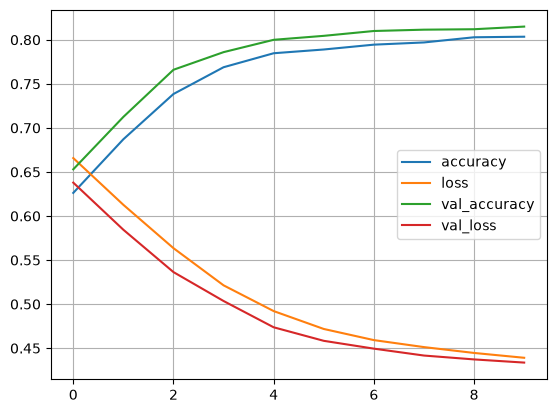

In [7]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()